# Grammar Scoring Engine for Spoken English — SHL Hiring Assessment 2026

**Task.** Predict a 1–5 grammar score (MOS Likert, averaged rater scores) for a 45–60 s English speech clip.
769 labelled training clips, 216 test clips. Leaderboard metrics: Pearson correlation and RMSE.

**Approach in one line.** *Listen → write down exactly what was said → measure grammar errors and fluency → learn the mapping to the score.*

```
 audio ──► Whisper large-v3-turbo ──► transcript + word timings + confidence ─┐
   │                                                                           ├─► 40-ish features ─► Ridge / LightGBM ─► blend ─► score
   └────► CrisperWhisper 2.0 turbo ──► verbatim + intended transcripts ────────┘   + sentence embedding
```

| Stage | What | Why |
|---|---|---|
| ASR (standard) | Whisper large-v3-turbo, verbatim prompt, no cross-segment conditioning, word timestamps | Accurate text, word timings for pauses, confidence scores |
| ASR (verbatim) | CrisperWhisper 2.0 turbo, *verbatim* and *intended* modes | Standard ASR silently fixes grammar errors and drops disfluencies — exactly the evidence being scored |
| Features | fluency, ASR confidence, lexical, LanguageTool error rate, GPT-2 perplexity, verbatim-vs-intended gap, sentence embedding | Each maps to a rubric criterion |
| Model | Ridge, Ridge + embedding, LightGBM; non-negative blend | Only 732 usable clips → small, regularised, explainable models |
| Validation | 5-fold × 3 repeats stratified CV, out-of-fold metrics | Honest estimate; single splits on 700 clips are noisy |

Heavy steps (transcription ≈ 30 min Whisper + several hours CrisperWhisper on an RTX 3050) are run by
`src/transcribe.py` and cached in `outputs/`. This notebook loads those caches, rebuilds features and models, and reports results.


In [1]:
import json, sys, os
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
sys.path.insert(0, 'src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import pearsonr
sns.set_theme(style='whitegrid', context='notebook')
DATA, OUT = Path('data/Dataset_Final'), Path('outputs')
TAG = 'v4_fs'
train = pd.read_csv(DATA/'train.csv'); test = pd.read_csv(DATA/'test.csv')
train['id'] = train.filename.str.extract(r'(\d+)').astype(int)
test['id'] = test.filename.str.extract(r'(\d+)').astype(int)
print(train.shape, test.shape)

Matplotlib is building the font cache; this may take a moment.


(769, 3) (216, 3)


## 1. Data exploration

Two findings shape everything that follows:
1. **Score 0.0 is not on the 1–5 rubric.** All 37 clips labelled 0.0 are exactly the files numbered ≥ 5000, every file ≥ 5000 is labelled 0.0, and **no test file is numbered ≥ 5000**. Their transcripts contain ordinary speech (some fluent), so 0.0 means *unscored / separate batch*, not *terrible grammar*. They are removed from training; predictions are clipped to the real 1–5 range.
2. Scores cluster on half-points 2.0–5.0; 1.0–1.5 are almost absent (4 clips).

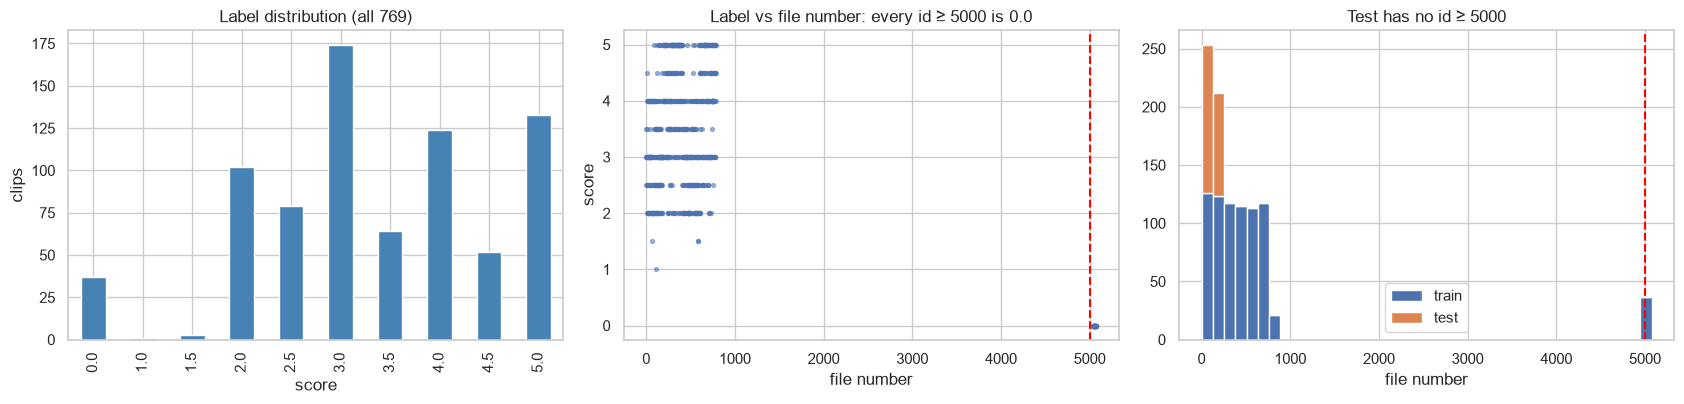

label==0  False  True 
id>=5000              
False       732      0
True          0     37


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
train.label.value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue')
ax[0].set(title='Label distribution (all 769)', xlabel='score', ylabel='clips')
ax[1].scatter(train.id, train.label, s=8, alpha=.5)
ax[1].axvline(5000, color='red', ls='--'); ax[1].set(title='Label vs file number: every id ≥ 5000 is 0.0', xlabel='file number', ylabel='score')
ax[2].hist([train.id, test.id], bins=40, label=['train', 'test'], stacked=True)
ax[2].axvline(5000, color='red', ls='--'); ax[2].legend(); ax[2].set(title='Test has no id ≥ 5000', xlabel='file number')
plt.tight_layout(); plt.show()
print(pd.crosstab(train.id >= 5000, train.label == 0, rownames=['id>=5000'], colnames=['label==0']))

## 2. ASR choice: why verbatim transcription matters

Same clips, three transcripts. Standard Whisper **corrects grammar** (*"Everyone has goal"* → *"has **a** goal"*),
**drops** cut-off words and repeats, and occasionally **hallucinates** text. CrisperWhisper verbatim keeps them and tags fillers (`[UM]`, `[UH]`);
its *intended* mode gives the cleaned version, so the verbatim↔intended gap directly measures how much repair the speech needs.

In [3]:
rows = json.load(open(OUT/'asr_compare.json', encoding='utf-8'))
show = {'audio_167.wav', 'audio_105.wav', 'audio_28.wav', 'audio_688.wav'}
pd.set_option('display.max_colwidth', 260)
pd.DataFrame([{'file': r['filename'], 'label': r['label'],
               'Whisper': r['whisper']['text'][:240],
               'Crisper verbatim': r['crisper']['verbatim'][:240],
               'Crisper intended': r['crisper']['intended'][:240]}
              for r in rows if r['filename'] in show])

,file,label,Whisper,Crisper verbatim,Crisper intended
0,audio_105.wav,2.0,"Crowded market has many people, uh, the market, which have got crowded, crowded people, uh, the people unable to buy anything, uh, with the people, people who, who were around them, in the, in the crowded market, uh, there is a, uh, uh, ful","Crowded market has many people [UH] the market which have got crowded ma- crowded people [UH] the people unable to buy anything [UH] with the people, people who who were around them. In the co- in the crowded market [UH] there is a [UH] [UH","Crowded market has many people. The market which have crowded crowded people are the people unable to buy anything with the people, people who were around them. In the crowded market there is a full of crowd that people can't buy easily any"
1,audio_167.wav,3.0,"Everyone has a goal in life. In my life, I have two goals. One is long-term goal and one is short-term goal. Firstly, my short-term goal is to achieve my bucket list by getting a job with my own money. And my long-term goal is to build a ho","Everyone has goal in life. In my life, I have two goals. One is long term goal and one is short term goal. Firstly, my short term goal is to achieve to achieve my bucket list by getting a job [UM] with my own money. And my long term goal is","Everyone has a goal in life. In my life, I have two goals. One is long-term goal and one is short-term goal. Firstly, my short-term goal is to achieve my bucket list by getting a job with my own money. And my long-term goal is to build a ho"
2,audio_28.wav,3.0,"Yeah, that was when I, when I was child, you know, I was, uh, 12 years old, that was in Cucuta, because I was born there, you know, I am a Colombian citizen, so, uh, every day, we have, like, 30 minutes or one hour to have breakfast, to hav","Yeah, that was when I when I was child, you know, I was [UH] twelve years old. That was in Cucuta because I was born there. You know, I am a Colombian citizen. So [UH] every day we have like thirty minutes or one hour to have breakfast, to","That was when I was a child. I was 12 years old. That was in Cucuta because I was born there. I am a Colombian citizen. So every day we have 30 minutes or 1 hour to have breakfast, to have lunch. So we enjoy that time with some friends. We"
3,audio_688.wav,5.0,"The playground looks like an average school playground with some basketball hoops, some slides, some swings, and a sandbox in the middle. Um, I can see that some of the popular activities are playing basketball and playing tag. um I can hea","The playground looks like an average school playground with some basketball hoops, some slides, some swings, and a sandbox in the middle [UM] I can see that some of the popular activities are playing basketball and playing tag [UM] I can he","The playground looks like an average school playground with some basketball hoops, some slides, some swings, and a sandbox in the middle. I can see that some of the popular activities are playing basketball and playing tag. I can hear a lot"


## 3. Features

| Group | Features | Rubric link |
|---|---|---|
| Fluency (Whisper word timings) | words/sec, articulation rate, pause ratio, pauses > 0.3 s and > 1 s per 100 words, longest pause | hesitation while planning sentences |
| ASR confidence | mean segment log-prob, word-probability mean / 10th pct, share of low-confidence words | broken / unclear structures are hard to decode |
| Lexical | word count, type-token ratio, mean word length, mean sentence length | control of complex structures |
| Grammar | LanguageTool error rate (casing / punctuation / style rules ignored — unreliable in ASR text) | direct error count |
| Language model | GPT-2 mean and 90th-pct token negative log-likelihood | ungrammatical word sequences are improbable |
| Verbatim (`cw_*`) | filler, cut-off and repeat rates, verbatim→intended edit similarity and edit ops, LanguageTool on verbatim | self-corrections, incomplete sentences |
| Embedding | all-mpnet-base-v2 sentence embedding of the transcript (768-d) | overall language quality |

(948, 46) | feature columns: ['speech_span', 'words_per_sec', 'articulation_rate', 'pause_ratio', 'pauses_03', 'pauses_1s', 'mean_gap', 'max_gap', 'word_prob_mean', 'word_prob_p10', 'low_prob_frac', 'seg_logprob_mean', 'seg_logprob_min', 'no_speech_max', 'compression_ratio_mean', 'n_words', 'n_content_words', 'filler_rate', 'repeat_rate', 'ttr', 'mean_word_len', 'mean_sent_len', 'lt_err_rate', 'lt_grammar_rate', 'lm_nll', 'lm_nll_p90', 'cola_mean', 'cola_min', 'cola_bad_frac', 'cw_n_words', 'cw_filler_rate', 'cw_cutoff_rate', 'cw_repeat_rate', 'cw_event_count', 'cw_clean_ratio', 'cw_edit_sim', 'cw_edit_ops', 'cw_lt_err_rate', 'cw_lt_grammar_rate', 'llm_score', 'llm_errors', 'llm_err_rate', 'fs_llm_score', 'fs_llm_errors', 'fs_llm_err_rate']


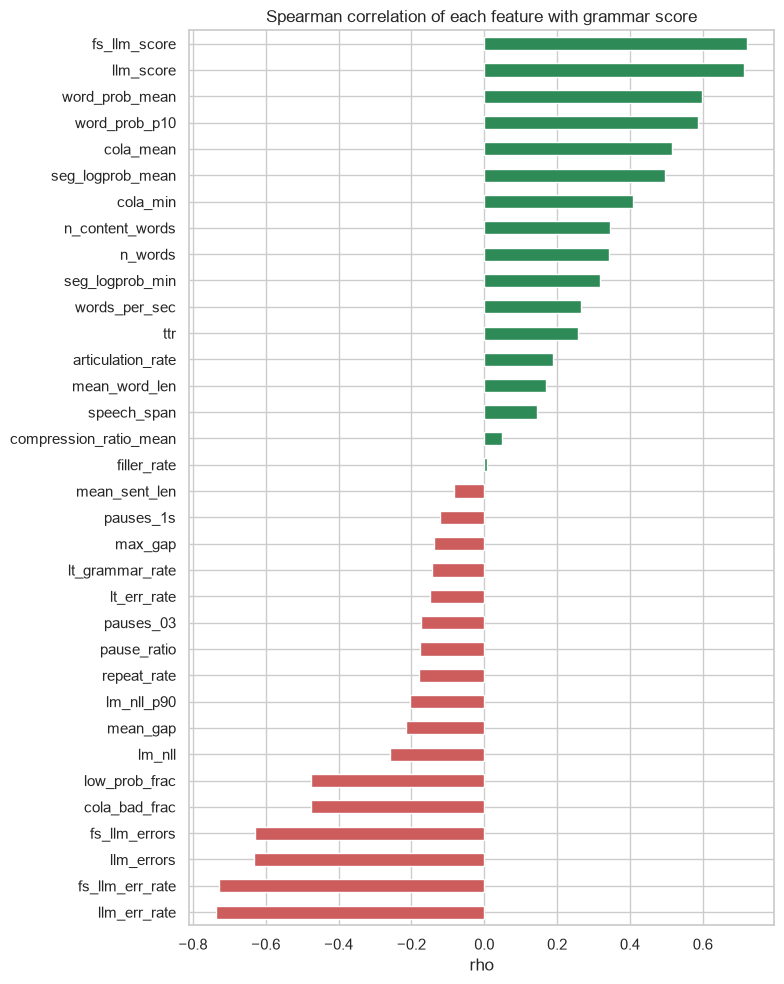

In [4]:
# Features are built by `python src/features.py` (LanguageTool, GPT-2, CoLA and the
# embedding take ~20 min on CPU), so the notebook loads the saved table.
feats = pd.read_parquet(OUT/'features.parquet')
print(feats.shape, '| feature columns:', [c for c in feats.columns if c != 'split'])
lab = train.set_index('filename').label
# keys are 'split/filename' (212 test files reuse train filenames for different audio)
tr = feats[feats.index.str.startswith('train/')].copy()
tr['label'] = lab.reindex(tr.index.str[len('train/'):]).values
tr = tr[tr.label > 0]
corr = tr.drop(columns=['split']).corr(method='spearman')['label'].drop('label').dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 10))
corr.plot.barh(ax=ax, color=np.where(corr > 0, 'seagreen', 'indianred'))
ax.set(title='Spearman correlation of each feature with grammar score', xlabel='rho'); plt.tight_layout(); plt.show()

## 4. Models and cross-validation

Repeated stratified 5-fold CV (3 repeats). Every clip is predicted by models that never saw it (*out-of-fold*, OOF).
OOF RMSE/Pearson is the honest estimate of test performance and is what model choices were based on.
The blend uses non-negative least-squares weights on the OOF predictions.

In [5]:
# Re-run training with exactly the settings stored for this model version.
import subprocess
a = json.load(open(OUT/f'metrics_{TAG}.json'))['args']
args = ['--emb', a['emb'], '--tag', TAG] + (['--no-crisper'] if a['no_crisper'] else []) \
       + (['--audio-layer', str(a['audio_layer'])] if a.get('audio_layer') is not None else [])
print('python src/train.py', ' '.join(args))
print(subprocess.run([sys.executable, 'src/train.py', *args], capture_output=True, text=True).stdout)

python src/train.py --emb whisper_mpnet --tag v4_fs --no-crisper


train (732, 35)  test (216, 35)  emb 768d

Out-of-fold CV (honest estimate of test performance):
  ridge_feat   RMSE 0.6394   Pearson 0.7760
  ridge_emb    RMSE 0.6457   Pearson 0.7731
  svr_feat     RMSE 0.6430   Pearson 0.7750
  lgbm_feat    RMSE 0.6389   Pearson 0.7770
  blend weights: {'ridge_feat': np.float64(0.053), 'ridge_emb': np.float64(0.412), 'svr_feat': np.float64(0.309), 'lgbm_feat': np.float64(0.225)}
  blend        RMSE 0.6022   Pearson 0.8067

Training-data fit (same clips used for fitting -> optimistic):
  blend        RMSE 0.3709   Pearson 0.9395

wrote outputs/submission_v4_fs.csv



In [6]:
m = json.load(open(OUT/f'metrics_{TAG}.json'))
res = pd.DataFrame(m['cv']).T.rename(columns={'rmse': 'CV RMSE', 'pearson': 'CV Pearson'})
res.loc['blend (training fit)'] = [m['train_fit']['rmse'], m['train_fit']['pearson']]
print('blend weights:', {k: round(v, 3) for k, v in m['weights'].items()})
res.round(4)

blend weights: {'ridge_feat': 0.053, 'ridge_emb': 0.412, 'svr_feat': 0.309, 'lgbm_feat': 0.225}


,CV RMSE,CV Pearson
ridge_feat,0.6394,0.7760
ridge_emb,0.6457,0.7731
svr_feat,0.6430,0.7750
lgbm_feat,0.6389,0.7770
blend,0.6022,0.8067
blend (training fit),0.3709,0.9395


## 5. ⚠️ Training-data RMSE (compulsory)

Final models refit on **all 732 scored training clips** and evaluated on those same clips.
This number is optimistic by construction (the model has seen the answers), so the out-of-fold CV RMSE above is the figure to trust for generalisation.

In [7]:
oof = pd.read_csv(OUT/f'oof_{TAG}.csv')
rm = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(f"TRAINING-DATA RMSE  : {rm(oof.label, oof.train_fit.clip(1, 5)):.4f}   Pearson {pearsonr(oof.label, oof.train_fit)[0]:.4f}")
print(f"OUT-OF-FOLD CV RMSE : {rm(oof.label, oof.oof.clip(1, 5)):.4f}   Pearson {pearsonr(oof.label, oof.oof)[0]:.4f}")

TRAINING-DATA RMSE  : 0.3709   Pearson 0.9394
OUT-OF-FOLD CV RMSE : 0.6022   Pearson 0.8067


## 6. Error analysis

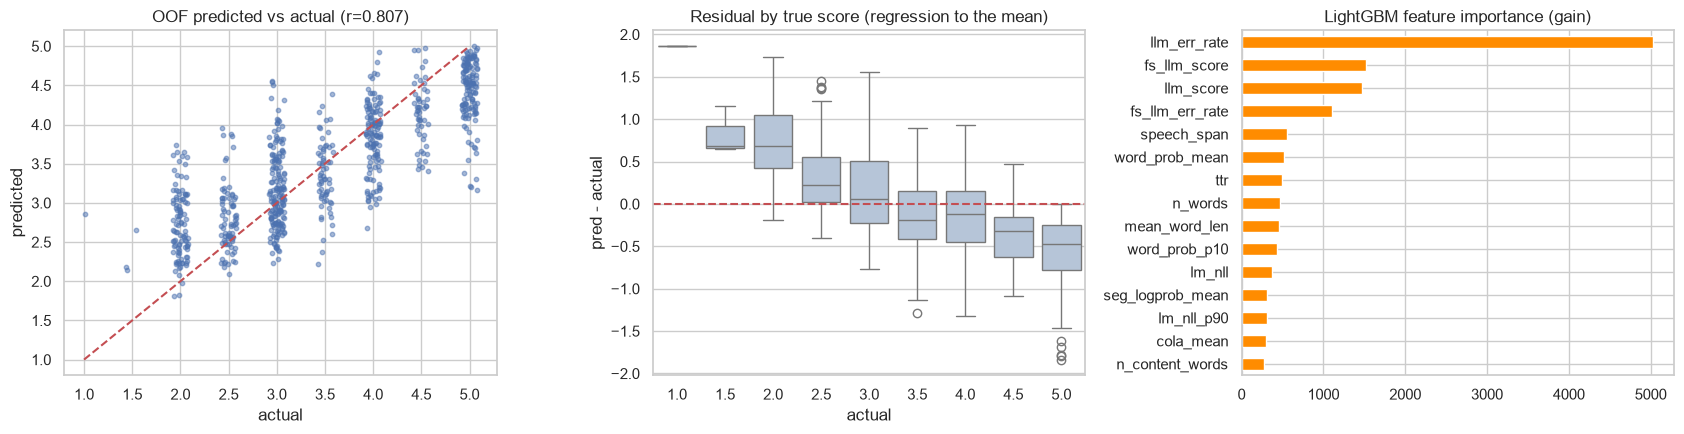

In [8]:
p = oof.oof.clip(1, 5); res_ = p - oof.label
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(oof.label + np.random.uniform(-.08, .08, len(oof)), p, s=10, alpha=.5)
ax[0].plot([1, 5], [1, 5], 'r--'); ax[0].set(title=f'OOF predicted vs actual (r={pearsonr(oof.label, p)[0]:.3f})', xlabel='actual', ylabel='predicted')
sns.boxplot(x=oof.label, y=res_, ax=ax[1], color='lightsteelblue'); ax[1].axhline(0, color='r', ls='--')
ax[1].set(title='Residual by true score (regression to the mean)', xlabel='actual', ylabel='pred - actual')
imp = pd.read_csv(OUT/f'importance_{TAG}.csv', index_col=0).iloc[:, 0].head(15)[::-1]
imp.plot.barh(ax=ax[2], color='darkorange'); ax[2].set(title='LightGBM feature importance (gain)')
plt.tight_layout(); plt.show()

**Reading the plots.** Predictions are compressed toward the mean (≈3.5): extreme scores (2.0, 5.0) are under-/over-predicted —
typical for regression on noisy averaged ratings with ~700 samples. Errors are largest for clips where ASR itself struggles
(heavy accent / noisy audio), because then transcript-derived grammar evidence is unreliable.

## 7. Submission

In [9]:
sub = pd.read_csv(OUT/f'submission_{TAG}.csv')
assert len(sub) == 216 and set(sub.filename) == set(test.filename)
sub.to_csv('submission.csv', index=False)
print(sub.label.describe()); sub.head()

count    216.000000
mean       3.344711
std        0.754942
min        1.816697
25%        2.761993
50%        3.221794
75%        3.924328
max        5.000000
Name: label, dtype: float64


,filename,label
0,audio_128.wav,3.130326
1,audio_156.wav,3.491767
2,audio_19.wav,4.436669
3,audio_108.wav,2.190042
4,audio_206.wav,2.552725


## 8. Summary & limitations

* **Key insights:** (1) the 0.0 labels are an unscored batch absent from test — removing them matters more than any model tweak;
  (2) standard ASR hides grammar errors, so a verbatim ASR is used alongside it.
* **Why simple models:** 732 noisy labels; Ridge/SVR/LightGBM on interpretable features are stable under CV and easy to explain.
* **What moved the score:** the Claude rubric judge (public RMSE 0.496 → 0.408), then few-shot calibration with 11 rater-scored anchors (→ 0.403). CoLA and extra LLM runs were neutral under CV and are reported, not hidden.
* **Limitations:** ASR errors on heavily-accented speech look like grammar errors; LanguageTool is tuned for written text; CrisperWhisper weights are non-commercial-research licensed (fine for this assessment, would need a licence or the Whisper-only path for production).
* **Next steps:** fine-tune a small encoder (e.g. DeBERTa-v3) on verbatim transcripts with 5-fold CV; add acoustic embeddings (WavLM) for pronunciation-independent fluency cues.